<a href="https://colab.research.google.com/github/lPragathi/RNN-PROJECT/blob/main/RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data variables not found in memory. Re-generating synthetic dataset...
Data successfully prepared. Train shape: torch.Size([944, 20, 1]), Test shape: torch.Size([236, 20, 1])

Training the Classic RNN model...
Epoch [10/50], Loss: 0.023755
Epoch [20/50], Loss: 0.022678
Epoch [30/50], Loss: 0.019067
Epoch [40/50], Loss: 0.017239
Epoch [50/50], Loss: 0.017389

Evaluating and generating predictions for Classic RNN...


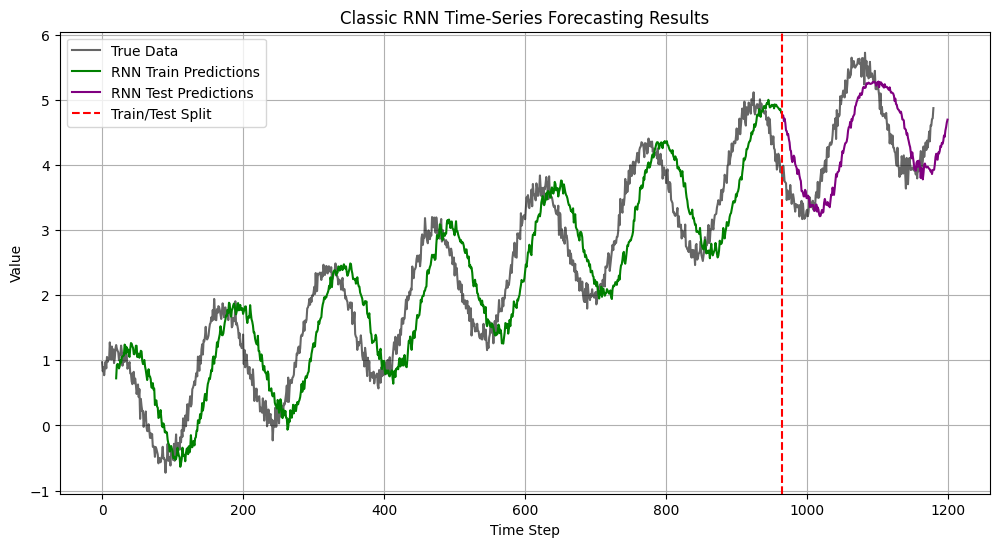

Classic RNN evaluation complete! Results plotted and saved to 'rnn_forecast_results.png'.


In [3]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Automatically check and recreate synthetic data if runtime is cleared
if 'X_train' not in globals():
    print("Data variables not found in memory. Re-generating synthetic dataset...")
    torch.manual_seed(42)
    np.random.seed(42)

    def generate_data(seq_length, num_samples=1200):
        time = np.linspace(0, 50, num_samples)
        data = np.sin(time) + 0.1 * time + np.random.normal(0, 0.1, num_samples)
        xs, ys = [], []
        for i in range(len(data) - seq_length):
            xs.append(data[i:i + seq_length])
            ys.append(data[i + seq_length])
        return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32)

    SEQ_LENGTH = 20
    X, y = generate_data(SEQ_LENGTH)
    X = torch.tensor(X).unsqueeze(-1)
    y = torch.tensor(y).unsqueeze(-1)

    train_size = int(len(X) * 0.8)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]
    print(f"Data successfully prepared. Train shape: {X_train.shape}, Test shape: {X_test.shape}\n")

# ==========================================
# 2. MODEL ARCHITECTURE (RNN)
# ==========================================
class RNNPredictor(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=32, num_layers=1, output_dim=1):
        super(RNNPredictor, self).__init__()
        self.rnn = nn.RNN(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # RNN output shape: [Batch Size, Seq Length, Hidden Dim]
        out, _ = self.rnn(x)
        # Take the output from the last time step
        out = self.fc(out[:, -1, :])
        return out

rnn_model = RNNPredictor()
rnn_criterion = nn.MSELoss()
rnn_optimizer = optim.Adam(rnn_model.parameters(), lr=0.01)

# ==========================================
# 3. RNN MODEL TRAINING
# ==========================================
print("Training the Classic RNN model...")
EPOCHS = 50
BATCH_SIZE = 64

for epoch in range(EPOCHS):
    rnn_model.train()
    total_loss = 0

    for i in range(0, len(X_train), BATCH_SIZE):
        X_batch = X_train[i:i+BATCH_SIZE]
        y_batch = y_train[i:i+BATCH_SIZE]

        # Forward pass
        outputs = rnn_model(X_batch)
        loss = rnn_criterion(outputs, y_batch)

        # Backward and optimize
        rnn_optimizer.zero_grad()
        loss.backward()
        rnn_optimizer.step()

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {total_loss / math.ceil(len(X_train)/BATCH_SIZE):.6f}")

# ==========================================
# 4. EVALUATION & VISUALIZATION (RNN)
# ==========================================
print("\nEvaluating and generating predictions for Classic RNN...")
rnn_model.eval()
with torch.no_grad():
    rnn_train_predictions = rnn_model(X_train).numpy()
    rnn_test_predictions = rnn_model(X_test).numpy()

# Plotting results
plt.figure(figsize=(12, 6))
plt.plot(np.arange(len(y)), y.numpy(), label="True Data", color="black", alpha=0.6)
plt.plot(np.arange(SEQ_LENGTH, train_size + SEQ_LENGTH), rnn_train_predictions, label="RNN Train Predictions", color="green")
plt.plot(np.arange(train_size + SEQ_LENGTH, len(y) + SEQ_LENGTH), rnn_test_predictions, label="RNN Test Predictions", color="purple")
plt.axvline(x=train_size + SEQ_LENGTH, color="red", linestyle="--", label="Train/Test Split")
plt.title("Classic RNN Time-Series Forecasting Results")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig("rnn_forecast_results.png")
plt.show()
print("Classic RNN evaluation complete! Results plotted and saved to 'rnn_forecast_results.png'.")

### 6. Linear Regression Baseline
To compare our deep learning sequence models against a simple linear trend, we will fit a classic Linear Regression model to the dataset.

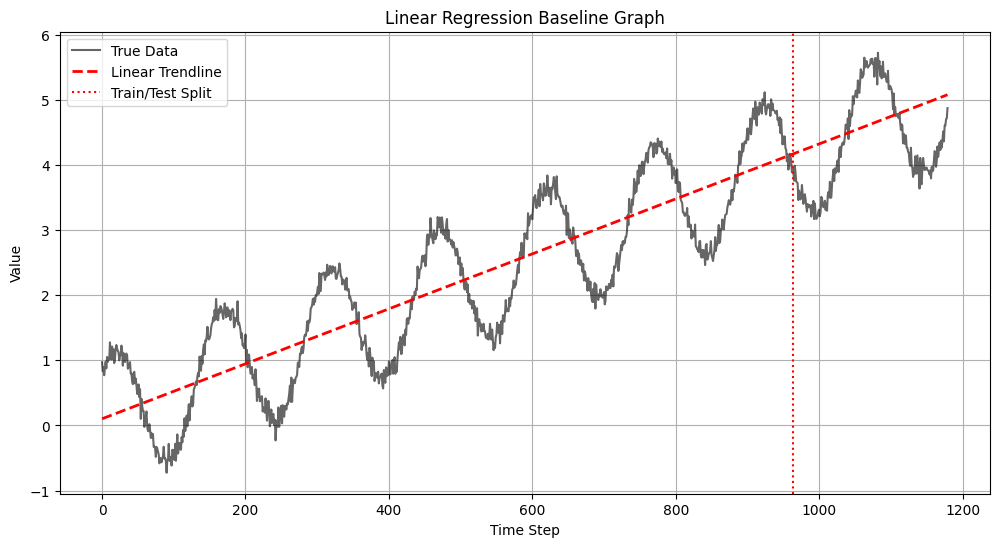

Linear Regression formula: y = 0.0042 * x + 0.1030


In [4]:
from sklearn.linear_model import LinearRegression

# Prepare data for Linear Regression (mapping Time Step to Value)
X_time = np.arange(len(y)).reshape(-1, 1)
y_val = y.numpy().reshape(-1, 1)

X_time_train = X_time[:train_size + SEQ_LENGTH]
y_val_train = y_val[:train_size + SEQ_LENGTH]

# Fit Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(X_time_train, y_val_train)

# Predict over the entire time span
linear_predictions = linear_model.predict(X_time)

# Plotting linear baseline results
plt.figure(figsize=(12, 6))
plt.plot(X_time, y_val, label="True Data", color="black", alpha=0.6)
plt.plot(X_time, linear_predictions, label="Linear Trendline", color="red", linestyle="--", linewidth=2)
plt.axvline(x=train_size + SEQ_LENGTH, color="red", linestyle=":", label="Train/Test Split")
plt.title("Linear Regression Baseline Graph")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig("linear_baseline_results.png")
plt.show()
print(f"Linear Regression formula: y = {linear_model.coef_[0][0]:.4f} * x + {linear_model.intercept_[0]:.4f}")